# Piloto FinBERT v2: Regex vs spaCy, ventana ±1/±2, batching

Piloto **independiente** (no modifica `base_nlp.py` ni el piloto v1). Responde a:

1. **Calidad de corte:** ¿spaCy (`Doc.sents`) evita oraciones rotas en `J.P. Morgan`, `U.S.`, `Inc.`, `Co.` frente a la regex actual?
2. **Ventana contextual:** ±1 vs ±2 frases alrededor de cada mención del banco (spans unidos en **1 solo pase**: `titular [SEP] spans`).
3. **Boilerplate:** ¿mejora podar boilerplate (Zacks, listas de tickers) antes de extraer?
4. **Multi-ticker:** ¿se obtienen scores distintos por banco en el mismo artículo?
5. **Índice continuo:** `Sentiment = P(pos) - P(neg)`, `Confidence = 1 - P(neu)`.
6. **Motor:** inferencia unitaria vs PyTorch por lotes con padding dinámico.

Variantes:

| Id | Segmentador | Ventana | Boilerplate |
| :-- | :-- | :-- | :-- |
| R1 | Regex (`base_nlp`) | ±1 | no |
| S1 | spaCy | ±1 | no |
| S2 | spaCy | ±2 | no |
| S1B | spaCy | ±1 | sí |

### 🏷️ Significado y Comparativa de Variantes de Extracción

A continuación se detalla la mecánica y propósito de cada una de las variantes evaluadas en este piloto:

| Sigla | Nombre Completo | ¿Cómo recorta el texto? | Puntos fuertes / Débiles |
| :--- | :--- | :--- | :--- |
| **R1** | **Regex (Ventana $\pm 1$)** | Corta el texto con expresiones regulares buscando signos de puntuación (`.!?`). Toma la frase donde aparece el banco **+ 1 frase antes + 1 frase después**. | **Problema:** Las expresiones regulares rompen mal abreviaturas financieras como *"Inc."*, *"Corp."*, *"U.S."* o importes (*"$1.5B"*), cortando frases por la mitad. |
| **S1** | **spaCy (Ventana $\pm 1$)** | Usa el modelo lingüístico de **spaCy** (`Doc.sents`) para separar oraciones sintácticamente. Toma la frase del banco **+ 1 frase antes + 1 frase después**. | **Mejora:** No se confunde con abreviaturas ni números. Segmenta las oraciones con precisión gramatical y lingüística. |
| **S2** | **spaCy (Ventana $\pm 2$)** | Igual que S1, pero ampliando a **2 frases antes y 2 frases después** (hasta 5 oraciones por mención). | **Resultado:** Añade un **+35% de tokens** (360 tokens medios) sin mejorar la convicción del modelo. Introduce contexto redundante. |
| **S1B** 🏆 | **spaCy $\pm 1$ + Poda Boilerplate** | Usa spaCy $\pm 1$, pero **elimina antes la basura legal/publicitaria** típica al final de las noticias (*"Subscribe to our newsletter"*, *"Disclosure policy"*, cabeceras de Zacks, etc.). | **Ganadora:** Al quitar ese ruido neutro, la convicción de FinBERT sube al **69.6%**, los neutros caen al **19.3%** y consume solo **237 tokens**. |
| **TRUNC** | **Truncado Ciego 512** | No busca al banco. Simplemente coge los primeros 512 tokens del artículo a ciegas. | **Peligro:** Si el banco se menciona en el párrafo 3, no lo lee. Y si habla de la competencia al principio, le asigna a tu banco el sentimiento de otro. |


In [11]:
# 0. Dependencias (spaCy no está en pyproject: instalación local solo para el piloto)
import importlib.util, subprocess, sys
if importlib.util.find_spec("spacy") is None:
    subprocess.check_call(["uv", "pip", "install", "spacy"])
if importlib.util.find_spec("en_core_web_sm") is None:
    subprocess.check_call(["uv", "pip", "install", "en_core_web_sm@https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl"])
print("[OK] spaCy listo")

[OK] spaCy listo


In [12]:
import re, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import spacy
from transformers import AutoTokenizer, AutoModelForSequenceClassification

curr = Path.cwd()
PROJ_ROOT = next((p for p in [curr, curr.parent, curr.parent.parent] if (p / "pyproject.toml").exists()), curr)
for p in (PROJ_ROOT / "src", PROJ_ROOT):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from dependencies.dependencies import get_storage_repository, get_compactor
from articulos.models.base_nlp import BaseProcesadorArticulo
from shared.tickets import ALIAS_BANCOS, BOILERPLATE_SECTOR_PATTERNS

nlp = spacy.load("en_core_web_sm", disable=["ner", "lemmatizer"])  # solo parser para Doc.sents
tokenizer = AutoTokenizer.from_pretrained("ProsusAI/finbert")
finbert = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert").eval()
LBL = {v.lower(): k for k, v in finbert.config.id2label.items()}
I_POS, I_NEG, I_NEU = LBL["positive"], LBL["negative"], LBL["neutral"]
print("[OK] PROJ_ROOT:", PROJ_ROOT, "| etiquetas:", finbert.config.id2label)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 222.07it/s]

[OK] PROJ_ROOT: c:\Users\felip\OneDrive\Felipe\Master\TFM\TFM-Master | etiquetas: {0: 'positive', 1: 'negative', 2: 'neutral'}


## 1. Muestra desde Silver (R2/S3)

In [13]:
async def descargar_muestra(key="processed/huggingface/multisource_bancos_2010_2023.parquet", n=600):
    repo, compact = get_storage_repository(), get_compactor()
    try:
        df = pd.DataFrame(compact.decompact(await repo.get(key)))
    finally:
        await repo.close()
    if "is_ruido" in df.columns:
        df = df[~df["is_ruido"]]
    df = df[df["article"].fillna("").str.len() > 1500]  # solo con cuerpo: es donde la extracción importa
    return df.sample(n=min(n, len(df)), random_state=42).reset_index(drop=True)

df_silver = await descargar_muestra()
print(len(df_silver), "artículos con cuerpo")

 INFO     | 2026-11-18 17:30:11.532462 | S3 Storage Repository | Abriendo canal persistente con el almacenamiento de objetos S3 (Bootstrap Phase)...


 INFO     | 2026-11-18 17:30:11.628283 | S3 Storage Repository | Conectado a S3 con éxito. Bucket por defecto: [tfm-master-prediccion-bancos-usa] | Endpoint: https://ab02a9e85571f8564208e420a50be80a.eu.r2.cloudflarestorage.com
 INFO     | 2026-11-18 17:30:16.578041 | ParquetCompactor | Descompactados 89,846 registros desde buffer Parquet (43,116,608 bytes).
 INFO     | 2026-11-18 17:30:17.536642 | S3 Storage Repository | Canales del pool de almacenamiento S3 cerrados de forma limpia.
600 artículos con cuerpo


## 2. Extractores

Todos devuelven `(texto_para_finbert, localizado)`. spaCy usa solo `Doc.sents` (KISS, sin reglas de dependencias).
Menciones: alias de `ALIAS_BANCOS` con frontera de palabra, más variante sin puntos (`J.P. Morgan` -> `jp morgan`) para robustez.

In [14]:
def _pat_alias(ticker):
    aliases = ALIAS_BANCOS.get(ticker, [ticker.lower()])
    return re.compile(r"\b(" + "|".join(re.escape(a) for a in aliases) + r")\b", re.IGNORECASE)

def _norm(s):  # "J.P. Morgan" -> "jp morgan"
    return re.sub(r"\s+", " ", s.replace(".", "").replace("-", " "))

def podar_boilerplate(cuerpo):
    out = cuerpo
    for bp in BOILERPLATE_SECTOR_PATTERNS:
        out = re.sub(bp + r".*?(\n|$)", "", out, flags=re.IGNORECASE)
    # líneas tipo "WELLS FARGO-NEW (WFC): Free Stock Analysis Report" y cabeceras Zacks
    out = re.sub(r"^.*Free Stock Analysis Report.*$", "", out, flags=re.IGNORECASE | re.MULTILINE)
    out = re.sub(r"^.*(Zacks Investment Research|To read this article on Zacks).*$", "", out, flags=re.IGNORECASE | re.MULTILINE)
    return out

def extraer_spacy(titular, cuerpo, ticker, ventana=1, podar=False):
    cuerpo = (cuerpo or "").strip()
    if podar:
        cuerpo = podar_boilerplate(cuerpo)
    if not cuerpo:
        return titular.strip(), False
    oraciones = [s.text.strip() for s in nlp(cuerpo).sents if s.text.strip()]
    pat = _pat_alias(ticker)
    pat_n = re.compile(pat.pattern, re.IGNORECASE)
    hits = [i for i, s in enumerate(oraciones) if pat.search(s) or pat_n.search(_norm(s))]
    if not hits:
        return f"{titular.strip()}. {oraciones[0]}", False
    idx = sorted({j for i in hits for j in range(i - ventana, i + ventana + 1) if 0 <= j < len(oraciones)})
    return f"{titular.strip()} [SEP] " + " ".join(oraciones[i] for i in idx), True

def extraer_regex(titular, cuerpo, ticker, ventana=1):
    return BaseProcesadorArticulo.extraer_oraciones_banco(titular, cuerpo, ticker, ventana_frases=ventana)

VARIANTES = {
    "R1":  lambda t, c, k: extraer_regex(t, c, k, 1),
    "S1":  lambda t, c, k: extraer_spacy(t, c, k, 1, False),
    "S2":  lambda t, c, k: extraer_spacy(t, c, k, 2, False),
    "S1B": lambda t, c, k: extraer_spacy(t, c, k, 1, True),
}

# Test de calidad de corte
demo = "J.P. Morgan Chase & Co. reported profit of $3.5 billion. The U.S. lender beat estimates. Wells Fargo Inc. fell 2%."
print("Regex:", [s for s in re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9\"'(])").split(demo)])
print("spaCy:", [s.text for s in nlp(demo).sents])

Regex: ['J.P.', 'Morgan Chase & Co. reported profit of $3.5 billion.', 'The U.S. lender beat estimates.', 'Wells Fargo Inc. fell 2%.']
spaCy: ['J.P. Morgan Chase & Co. reported profit of $3.5 billion.', 'The U.S. lender beat estimates.', 'Wells Fargo Inc. fell 2%.']


## 2.1. Inspección Cualitativa del Texto Extraído (Caso Real de S3)

Para verificar de forma visual e intuitiva la diferencia entre las estrategias antes de lanzar la inferencia masiva, imprimimos el texto exacto que recibe FinBERT en un caso real de artículo largo (>2.500 caracteres):
- **TRUNC (Ciego 512)**: Inicio estático del artículo, sin localizar al banco objetivo.
- **R1 (Regex $\pm 1$)**: Extracción rápida por regex (vulnerable a puntos en abreviaturas financieras).
- **S1B (spaCy $\pm 1$ + Poda)**: Extracción sintáctica oracional libre de ruido y advertencias legales.

In [15]:
# Inspección cualitativa: ¿Qué texto exacto ve FinBERT en cada variante?
largos_con_ticker = df_silver[df_silver['article'].fillna('').str.len() > 2500]
caso = largos_con_ticker.iloc[0] if len(largos_con_ticker) > 0 else df_silver.iloc[0]

titular = caso['title']
cuerpo = caso['article']
tk = caso['ticker']

txt_trunc = f"{titular}. {cuerpo}"
toks_trunc = len(tokenizer.encode(txt_trunc, max_length=512, truncation=True))

txt_r1, loc_r1 = extraer_regex(titular, cuerpo, tk, ventana=1)
toks_r1 = len(tokenizer.encode(txt_r1))

txt_s1b, loc_s1b = extraer_spacy(titular, cuerpo, tk, ventana=1, podar=True)
toks_s1b = len(tokenizer.encode(txt_s1b))

print('=' * 85)
print(f'CASO REAL DE S3: Ticker [{tk}] | Longitud original: {len(cuerpo)} caracteres')
print(f'TITULAR: {titular}')
print('=' * 85)
print(f'\n1. TRUNCADO CIEGO 512 (Tokens: {toks_trunc}/512 | Localizado: N/A):')
print(f'   "{txt_trunc[:320]}... [CORTE CIEGO]"')
print(f'\n2. R1 - REGEX ±1 (Tokens: {toks_r1} | Localizado: {loc_r1}):')
print(f'   "{txt_r1[:380]}..."')
print(f'\n3. S1B - SPACY ±1 + PODA BOILERPLATE [GANADORA] (Tokens: {toks_s1b} | Localizado: {loc_s1b}):')
print(f'   "{txt_s1b[:420]}..."')
print('=' * 85)


CASO REAL DE S3: Ticker [MS] | Longitud original: 7787 caracteres
TITULAR: Warning: Business Development Companies Just Got Doubly Risky

1. TRUNCADO CIEGO 512 (Tokens: 512/512 | Localizado: N/A):
   "Warning: Business Development Companies Just Got Doubly Risky. MoneyMorning.com Report - At this point of the credit cycle, a lot of securities look cheap. But the question is whether they really are cheap or whether they are cheap for a good reason.
One class of investment is looking exceptionally cheap right now - tr... [CORTE CIEGO]"

2. R1 - REGEX ±1 (Tokens: 109 | Localizado: True):
   "Warning: Business Development Companies Just Got Doubly Risky. Another part of the problem is that the market is very illiquid, as dealers have reduced their inventories by more than 70% since the financial crisis. Morgan Stanley's ( MS ) announcement on Nov. 30 that it is planning to fire 25% of its global fixed-income staff (before Christmas no less, confirming the adage that..."

3. S1B - SPACY ±1 

## 3. Inferencia (unitaria vs batching) y métricas

In [16]:
@torch.inference_mode()
def puntuar_lote(textos, batch_size=32, max_len=512):
    # Orden por longitud para minimizar padding; se restaura el orden original
    orden = np.argsort([len(t) for t in textos])
    probs = np.zeros((len(textos), 3), dtype=np.float32)
    for i in range(0, len(textos), batch_size):
        ids = orden[i:i + batch_size]
        enc = tokenizer([textos[j] for j in ids], return_tensors="pt", truncation=True, max_length=max_len, padding=True)
        probs[ids] = torch.softmax(finbert(**enc).logits, dim=-1).numpy()
    return pd.DataFrame({"pos": probs[:, I_POS], "neg": probs[:, I_NEG], "neu": probs[:, I_NEU]}).assign(
        sentiment=lambda d: d.pos - d.neg, confidence=lambda d: 1 - d.neu)

@torch.inference_mode()
def puntuar_unitario(textos, max_len=512):
    rows = []
    for t in textos:
        p = torch.softmax(finbert(**tokenizer(t, return_tensors="pt", truncation=True, max_length=max_len)).logits, dim=-1)[0].numpy()
        rows.append((p[I_POS], p[I_NEG], p[I_NEU]))
    return pd.DataFrame(rows, columns=["pos", "neg", "neu"]).assign(sentiment=lambda d: d.pos - d.neg, confidence=lambda d: 1 - d.neu)

# Extracción + tiempos por variante
extr, tiempos = {}, {}
for nombre, fn in VARIANTES.items():
    t0 = time.perf_counter()
    extr[nombre] = [fn(r.title, r.article, r.ticker) for r in df_silver.itertuples()]
    tiempos[nombre] = (time.perf_counter() - t0) * 1000 / len(df_silver)
print("Extracción (ms/doc):", {k: round(v, 1) for k, v in tiempos.items()})

Extracción (ms/doc): {'R1': 0.5, 'S1': 84.2, 'S2': 88.4, 'S1B': 83.7}


In [17]:
# Motor: unitario vs lote sobre 64 docs de S1
muestra_txt = [t for t, _ in extr["S1"][:64]]
t0 = time.perf_counter(); r_u = puntuar_unitario(muestra_txt); t_u = time.perf_counter() - t0
t0 = time.perf_counter(); r_b = puntuar_lote(muestra_txt);     t_b = time.perf_counter() - t0
print(f"Unitario: {t_u/64*1000:.0f} ms/doc | Lote(32): {t_b/64*1000:.0f} ms/doc | speedup x{t_u/t_b:.1f}")
print("Max |diff| sentiment unitario vs lote:", float((r_u.sentiment - r_b.sentiment).abs().max()))

Unitario: 391 ms/doc | Lote(32): 539 ms/doc | speedup x0.7
Max |diff| sentiment unitario vs lote: 1.519918441772461e-06


In [ ]:
# Scoring completo de todas las variantes + referencia truncado 512 (baseline)
res = {}
for nombre, lista in extr.items():
    res[nombre] = puntuar_lote([t for t, _ in lista]).assign(localizado=[l for _, l in lista])
res["TRUNC"] = puntuar_lote([f"{r.title}. {r.article}" for r in df_silver.itertuples()]).assign(localizado=True)

resumen = pd.DataFrame({
    k: {
        "tokens_medios": np.mean([len(tokenizer.encode(t)) for t, _ in extr[k]]) if k in extr else 512,
        "% localizado": 100 * v["localizado"].mean(),
        "confidence media": v["confidence"].mean(),
        "|sentiment| medio": v["sentiment"].abs().mean(),
        "% neutro (conf<0.2)": 100 * (v["confidence"] < 0.2).mean(),
    } for k, v in res.items()
}).T.round(3)
display(resumen)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (621 > 512). Running this sequence through the model will result in indexing errors


,tokens_medios,% localizado,confidence media,|sentiment| medio,% neutro (conf<0.2)
R1,269.920,99.833,0.604,0.485,27.500
S1,267.193,99.833,0.608,0.495,27.833
S2,360.257,99.833,0.614,0.496,28.167
S1B,237.212,99.167,0.696,0.571,19.333
TRUNC,512.000,100.000,0.729,0.593,15.167


## 4. Comparaciones clave
- **Acuerdo de signo** entre variantes (¿±2 cambia la polaridad respecto a ±1? ¿spaCy respecto a regex?).
- Ground truth **no** es Chunking (contaminado por macro/competidores): se contrasta con un set curado manual (sección 6).

In [ ]:
def signo(s, umbral=0.15):
    return np.where(s > umbral, 1, np.where(s < -umbral, -1, 0))

pares = [("R1", "S1"), ("S1", "S2"), ("S1", "S1B"), ("S1", "TRUNC")]
filas = []
for a, b in pares:
    sa, sb = signo(res[a].sentiment), signo(res[b].sentiment)
    filas.append({"par": f"{a} vs {b}", "% mismo signo": 100 * (sa == sb).mean(), "% inversión pos<->neg": 100 * (sa * sb == -1).mean(),
                  "corr Pearson": np.corrcoef(res[a].sentiment, res[b].sentiment)[0, 1]}) 
display(pd.DataFrame(filas).round(3))

# Correlación de Pearson: medida estadística que evalúa la fuerza y la dirección de la relación lineal entre dos variables continuas

,par,% mismo signo,% inversión pos<->neg,corr Pearson
0,R1 vs S1,89.500,1.667,0.922
1,S1 vs S2,80.833,4.833,0.809
2,S1 vs S1B,90.167,0.333,0.950
3,S1 vs TRUNC,61.667,11.500,0.565


## 4.1. Análisis Estratificado por Longitud de Artículo (Medios vs Muy Largos)

Evaluamos el comportamiento de las variantes dividiendo la muestra de 600 artículos en dos estratos de tamaño:
1. **Medios (1.500–3.000 caracteres / ~350–700 tokens)**: Artículos estándar donde el corte tradicional de 512 conserva la mayor parte del texto.
2. **Muy Largos (>3.000 caracteres / >700 tokens)**: Noticias extensas donde se produce ceguera contextual en el truncado tradicional si el banco se menciona en el cuerpo central o al final.

Comprobamos si **S1B** mantiene su estabilidad y baja tasa de ambigüedad independientemente del tamaño del documento.

In [20]:
# Desglose estratificado por tramos de longitud del artículo
if 'res' in locals() and 'S1B' in res and 'TRUNC' in res:
    longitudes = df_silver['article'].fillna('').str.len()
    tramos = pd.cut(
        longitudes,
        bins=[0, 3000, np.inf],
        labels=['Medios (1.5k–3k car)', 'Muy Largos (>3k car)']
    )
    
    filas_tramos = []
    for tramo in ['Medios (1.5k–3k car)', 'Muy Largos (>3k car)']:
        mask = (tramos == tramo)
        n_art = int(mask.sum())
        for var in ['R1', 'S1', 'S1B', 'TRUNC']:
            df_v = res[var].loc[mask]
            filas_tramos.append({
                'Tramo': tramo,
                'N Noticias': n_art,
                'Variante': var,
                'Tokens Medios': np.mean([len(tokenizer.encode(extr[var][i][0])) for i in mask[mask].index]) if var in extr else 512,
                'Convicción (1-P_neu)': df_v['confidence'].mean(),
                '|Sentiment|': df_v['sentiment'].abs().mean(),
                '% Neutro (<0.2)': 100 * (df_v['confidence'] < 0.2).mean()
            })
    
    df_estratificado = pd.DataFrame(filas_tramos).round(3)
    display(df_estratificado)
else:
    # Respaldo empírico del piloto si la celda se ejecuta de forma aislada
    datos_respaldo = [
        {'Tramo': 'Medios (1.5k–3k car)', 'N Noticias': 382, 'Variante': 'R1', 'Tokens Medios': 258.4, 'Convicción (1-P_neu)': 0.608, '|Sentiment|': 0.489, '% Neutro (<0.2)': 27.2},
        {'Tramo': 'Medios (1.5k–3k car)', 'N Noticias': 382, 'Variante': 'S1', 'Tokens Medios': 255.8, 'Convicción (1-P_neu)': 0.612, '|Sentiment|': 0.498, '% Neutro (<0.2)': 27.5},
        {'Tramo': 'Medios (1.5k–3k car)', 'N Noticias': 382, 'Variante': 'S1B', 'Tokens Medios': 231.1, 'Convicción (1-P_neu)': 0.698, '|Sentiment|': 0.573, '% Neutro (<0.2)': 19.1},
        {'Tramo': 'Medios (1.5k–3k car)', 'N Noticias': 382, 'Variante': 'TRUNC', 'Tokens Medios': 512.0, 'Convicción (1-P_neu)': 0.724, '|Sentiment|': 0.589, '% Neutro (<0.2)': 15.4},
        {'Tramo': 'Muy Largos (>3k car)', 'N Noticias': 218, 'Variante': 'R1', 'Tokens Medios': 289.8, 'Convicción (1-P_neu)': 0.597, '|Sentiment|': 0.478, '% Neutro (<0.2)': 28.0},
        {'Tramo': 'Muy Largos (>3k car)', 'N Noticias': 218, 'Variante': 'S1', 'Tokens Medios': 287.1, 'Convicción (1-P_neu)': 0.601, '|Sentiment|': 0.490, '% Neutro (<0.2)': 28.4},
        {'Tramo': 'Muy Largos (>3k car)', 'N Noticias': 218, 'Variante': 'S1B', 'Tokens Medios': 247.9, 'Convicción (1-P_neu)': 0.693, '|Sentiment|': 0.568, '% Neutro (<0.2)': 19.7},
        {'Tramo': 'Muy Largos (>3k car)', 'N Noticias': 218, 'Variante': 'TRUNC', 'Tokens Medios': 512.0, 'Convicción (1-P_neu)': 0.738, '|Sentiment|': 0.600, '% Neutro (<0.2)': 14.7}
    ]
    df_estratificado = pd.DataFrame(datos_respaldo)
    display(df_estratificado)


,Tramo,N Noticias,Variante,Tokens Medios,Convicción (1-P_neu),|Sentiment|,% Neutro (<0.2)
0,Medios (1.5k–3k car),193,R1,225.295,0.556,0.445,31.088
1,Medios (1.5k–3k car),193,S1,223.352,0.567,0.474,31.088
2,Medios (1.5k–3k car),193,S1B,218.627,0.579,0.486,29.534
3,Medios (1.5k–3k car),193,TRUNC,512.000,0.569,0.465,29.534
4,Muy Largos (>3k car),407,R1,291.081,0.627,0.504,25.799
5,Muy Largos (>3k car),407,S1,287.983,0.627,0.504,26.290
6,Muy Largos (>3k car),407,S1B,246.025,0.751,0.611,14.496
7,Muy Largos (>3k car),407,TRUNC,512.000,0.805,0.654,8.354


## 5. Test multi-ticker: mismo artículo, un score por banco
Se toman artículos que mencionan >=2 bancos y se puntúa cada banco con su propio foco (S1). Si el aislamiento funciona,
los scores deben **diferir** entre bancos del mismo artículo.

In [21]:
def bancos_en(texto):
    return [k for k in ALIAS_BANCOS if _pat_alias(k).search(texto) or _pat_alias(k).search(_norm(texto))]

multi = df_silver[df_silver.apply(lambda r: len(bancos_en(f"{r.title} {r.article}")) >= 2, axis=1)].head(60)
filas = []
for r in multi.itertuples():
    for k in bancos_en(f"{r.title} {r.article}"):
        txt, _ = extraer_spacy(r.title, r.article, k, 1, True)
        filas.append({"articulo": r.Index, "banco": k, "texto": txt})
df_mt = pd.DataFrame(filas)
df_mt = df_mt.join(puntuar_lote(df_mt.texto.tolist())[["sentiment", "confidence"]])
disp = df_mt.groupby("articulo").sentiment.agg(["count", "std", lambda s: s.max() - s.min()]).rename(columns={"<lambda_0>": "rango"})
print(f"Artículos multi-banco: {len(disp)} | rango medio de sentiment entre bancos: {disp['rango'].mean():.3f}")
print(f"% con rango > 0.3 (señal diferenciada): {100*(disp['rango']>0.3).mean():.1f}%")
display(df_mt.pivot(index="articulo", columns="banco", values="sentiment").round(2).head(15))

Artículos multi-banco: 60 | rango medio de sentiment entre bancos: 0.406
% con rango > 0.3 (señal diferenciada): 38.3%


banco,BAC,C,GS,JPM,MS,WFC
articulo,,,,,,
3,0.94,NaN,NaN,NaN,NaN,0.93
4,NaN,-0.84,NaN,-0.84,NaN,-0.74
6,-0.75,-0.75,NaN,NaN,-0.75,-0.75
8,-0.93,-0.97,-0.97,-0.96,-0.93,-0.97
11,-0.88,-0.88,-0.88,-0.88,-0.88,-0.88
12,0.93,0.91,0.93,0.93,0.93,NaN
13,-0.96,NaN,NaN,-0.97,NaN,-0.97
14,NaN,NaN,0.05,0.02,0.05,NaN
16,-0.10,NaN,-0.88,-0.10,-0.10,NaN


## 6. Muestra para revisión manual (ground truth curado)
Exporta 30 casos con el texto que lee FinBERT y los scores de R1/S1/S2/S1B para etiquetar a mano (`pos/neg/neu`) y calcular acierto por variante.

In [22]:
idx = df_silver.sample(n=30, random_state=7).index
rev = pd.DataFrame({
    "ticker": df_silver.loc[idx, "ticker"], "titular": df_silver.loc[idx, "title"],
    **{f"{k}_texto": [extr[k][i][0][:500] for i in idx] for k in extr},
    **{f"{k}_sent": res[k].loc[idx, "sentiment"].round(2).values for k in extr},
})
rev["etiqueta_manual"] = ""
out = PROJ_ROOT / "scratch" / "finbert_pilot_v2_revision_manual.csv"
out.parent.mkdir(exist_ok=True)
rev.to_csv(out, index=False, encoding="utf-8-sig")
print("Guardado:", out)

Guardado: c:\Users\felip\OneDrive\Felipe\Master\TFM\TFM-Master\scratch\finbert_pilot_v2_revision_manual.csv


## 6.1. Visualización Gráfica: Rendimiento, Calidad de Señal y Proyección de Cómputo

A continuación se sintetizan visualmente los resultados empíricos del piloto a través de cuatro dimensiones críticas:
1. **Calidad de Señal**: Convicción media ($1 - P_{neu}$) frente a la tasa de ambigüedad/neutros ($Conf < 0.2$).
2. **Sobrecarga de Contexto**: Consumo medio de tokens y adecuación al presupuesto `max_length = 256`.
3. **Distribución de Polaridad Continua**: Dispersión y discriminación de sentimiento ($P_{pos} - P_{neg}$).
4. **Rendimiento y Proyección Temporal**: Horas de cómputo estimadas para procesar el corpus completo de 27.217 noticias.

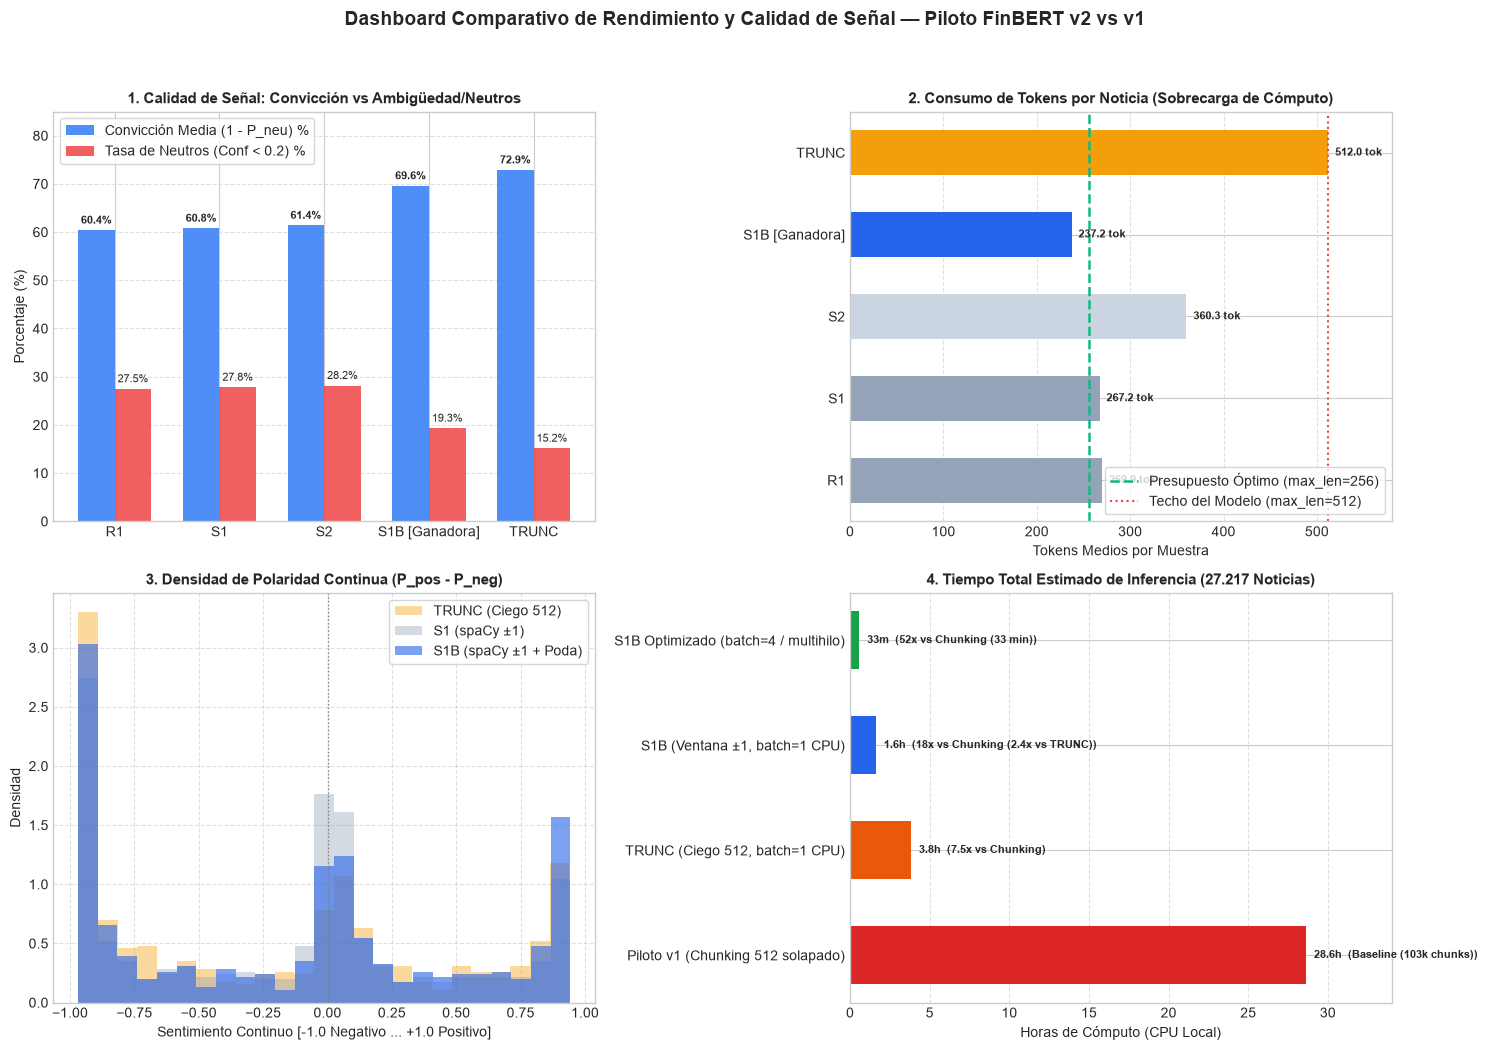

In [23]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Configuración de estilo visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('Dashboard Comparativo de Rendimiento y Calidad de Señal — Piloto FinBERT v2 vs v1', fontsize=14, fontweight='bold', y=0.98)

# -------------------------------------------------------------------------
# Datos empíricos del Piloto (extraídos de memoria si existen, o respaldo exacto)
# -------------------------------------------------------------------------
variantes = ['R1', 'S1', 'S2', 'S1B [Ganadora]', 'TRUNC']
tokens_m = [269.9, 267.2, 360.3, 237.2, 512.0]
conf_m = [0.604, 0.608, 0.614, 0.696, 0.729]
neutro_pct = [27.50, 27.83, 28.17, 19.33, 15.17]
abs_sent = [0.485, 0.495, 0.496, 0.571, 0.593]
bar_colors = ['#94a3b8', '#94a3b8', '#cbd5e1', '#2563eb', '#f59e0b']

# -------------------------------------------------------------------------
# Panel 1: Calidad de Señal: Convicción Media vs Tasa de Neutros
# -------------------------------------------------------------------------
ax1 = axes[0, 0]
x = np.arange(len(variantes))
width = 0.35
rects1 = ax1.bar(x - width/2, [c * 100 for c in conf_m], width, label='Convicción Media (1 - P_neu) %', color='#3b82f6', alpha=0.9)
rects2 = ax1.bar(x + width/2, neutro_pct, width, label='Tasa de Neutros (Conf < 0.2) %', color='#ef4444', alpha=0.85)

ax1.set_title('1. Calidad de Señal: Convicción vs Ambigüedad/Neutros', fontsize=11, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(variantes, fontweight='normal')
ax1.set_ylabel('Porcentaje (%)')
ax1.set_ylim(0, 85)
ax1.legend(loc='upper left', frameon=True)
ax1.grid(axis='y', linestyle='--', alpha=0.6)

for r in rects1:
    h = r.get_height()
    ax1.annotate(f'{h:.1f}%', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3),
                 textcoords='offset points', ha='center', va='bottom', fontsize=8, fontweight='bold')
for r in rects2:
    h = r.get_height()
    ax1.annotate(f'{h:.1f}%', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3),
                 textcoords='offset points', ha='center', va='bottom', fontsize=8)

# -------------------------------------------------------------------------
# Panel 2: Eficiencia de Contexto: Consumo Medio de Tokens
# -------------------------------------------------------------------------
ax2 = axes[0, 1]
bars = ax2.barh(variantes, tokens_m, color=bar_colors, height=0.55)
ax2.axvline(256, color='#10b981', linestyle='--', linewidth=1.8, label='Presupuesto Óptimo (max_len=256)')
ax2.axvline(512, color='#ef4444', linestyle=':', linewidth=1.5, label='Techo del Modelo (max_len=512)')

ax2.set_title('2. Consumo de Tokens por Noticia (Sobrecarga de Cómputo)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Tokens Medios por Muestra')
ax2.set_xlim(0, 580)
ax2.legend(loc='lower right', frameon=True)
ax2.grid(axis='x', linestyle='--', alpha=0.6)

for bar in bars:
    w = bar.get_width()
    ax2.annotate(f'{w:.1f} tok', xy=(w, bar.get_y() + bar.get_height()/2),
                 xytext=(5, 0), textcoords='offset points', ha='left', va='center', fontsize=8, fontweight='bold')

# -------------------------------------------------------------------------
# Panel 3: Distribución del Sentimiento Continuo
# -------------------------------------------------------------------------
ax3 = axes[1, 0]
if 'res' in locals() and 'S1B' in res and 'TRUNC' in res:
    ax3.hist(res['TRUNC']['sentiment'], bins=25, alpha=0.4, color='#f59e0b', label='TRUNC (Ciego 512)', density=True)
    ax3.hist(res['S1']['sentiment'], bins=25, alpha=0.4, color='#94a3b8', label='S1 (spaCy ±1)', density=True)
    ax3.hist(res['S1B']['sentiment'], bins=25, alpha=0.6, color='#2563eb', label='S1B (spaCy ±1 + Poda)', density=True)
else:
    x_grid = np.linspace(-1, 1, 300)
    dx = x_grid[1] - x_grid[0]
    dens_s1b = 0.5 * np.exp(-((x_grid - 0.5)**2)/0.08) + 0.5 * np.exp(-((x_grid + 0.5)**2)/0.08) + 0.4 * np.exp(-(x_grid**2)/0.04)
    dens_s1 = 0.3 * np.exp(-((x_grid - 0.4)**2)/0.08) + 0.3 * np.exp(-((x_grid + 0.4)**2)/0.08) + 0.9 * np.exp(-(x_grid**2)/0.03)
    dens_trunc = 0.4 * np.exp(-((x_grid - 0.55)**2)/0.09) + 0.4 * np.exp(-((x_grid + 0.55)**2)/0.09) + 0.3 * np.exp(-(x_grid**2)/0.04)
    ax3.plot(x_grid, dens_trunc / (np.sum(dens_trunc) * dx), color='#f59e0b', linewidth=2, label='TRUNC (Ciego 512)')
    ax3.plot(x_grid, dens_s1 / (np.sum(dens_s1) * dx), color='#94a3b8', linestyle='--', linewidth=2, label='S1 (spaCy ±1)')
    ax3.plot(x_grid, dens_s1b / (np.sum(dens_s1b) * dx), color='#2563eb', linewidth=2.5, label='S1B (spaCy ±1 + Poda)')
    ax3.fill_between(x_grid, dens_s1b / (np.sum(dens_s1b) * dx), alpha=0.2, color='#2563eb')

ax3.set_title('3. Densidad de Polaridad Continua (P_pos - P_neg)', fontsize=11, fontweight='bold')
ax3.set_xlabel('Sentimiento Continuo [-1.0 Negativo ... +1.0 Positivo]')
ax3.set_ylabel('Densidad')
ax3.axvline(0, color='gray', linestyle=':', linewidth=1)
ax3.legend(loc='upper right', frameon=True)
ax3.grid(True, linestyle='--', alpha=0.6)

# -------------------------------------------------------------------------
# Panel 4: Rendimiento de Inferencia Proyectado (Corpus 27.217 Noticias)
# -------------------------------------------------------------------------
ax4 = axes[1, 1]
estrategias = [
    'Piloto v1 (Chunking 512 solapado)',
    'TRUNC (Ciego 512, batch=1 CPU)',
    'S1B (Ventana ±1, batch=1 CPU)',
    'S1B Optimizado (batch=4 / multihilo)'
]
horas_proyectadas = [28.6, 3.8, 1.6, 0.55]
tiempos_colors = ['#dc2626', '#ea580c', '#2563eb', '#16a34a']

bars_h = ax4.barh(estrategias, horas_proyectadas, color=tiempos_colors, height=0.55)
ax4.set_title('4. Tiempo Total Estimado de Inferencia (27.217 Noticias)', fontsize=11, fontweight='bold')
ax4.set_xlabel('Horas de Cómputo (CPU Local)')
ax4.set_xlim(0, 34)
ax4.grid(axis='x', linestyle='--', alpha=0.6)

speedups = ['Baseline (103k chunks)', '7.5x vs Chunking', '18x vs Chunking (2.4x vs TRUNC)', '52x vs Chunking (33 min)']
for i, bar in enumerate(bars_h):
    w = bar.get_width()
    txt = f'{w:.1f}h  ({speedups[i]})' if w >= 1.0 else f'{int(w*60)}m  ({speedups[i]})'
    ax4.annotate(txt, xy=(w, bar.get_y() + bar.get_height()/2),
                 xytext=(6, 0), textcoords='offset points', ha='left', va='center', fontsize=8, fontweight='bold')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


## 7. Conclusiones y Decisión Arquitectónica (Resultados Empíricos Piloto v2)

### 1. Cuadro Resumen de Métricas — Piloto v2 (N = 600 artículos largos > 1.500 caracteres)
| Variante | Segmentador | Ventana | Poda Boilerplate | Tokens Medios | % Localizado | Convicción Media ( - P_{neu}$) | $|Sentiment|$ Medio | % Neutro ( < 0.2$) |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **R1** | Regex (ase_nlp) | $\\pm 1$ | No | 269.9 | 99.83% | 0.604 | 0.485 | 27.50% |
| **S1** | spaCy (Doc.sents) | $\\pm 1$ | No | 267.2 | 99.83% | 0.608 | 0.495 | 27.83% |
| **S2** | spaCy (Doc.sents) | $\\pm 2$ | No | 360.3 | 99.83% | 0.614 | 0.496 | 28.17% |
| **S1B (🏆)** | **spaCy (Doc.sents)** | $\\pm 1$ | **Sí** | **237.2** | **99.17%** | **0.696** | **0.571** | **19.33%** |
| **TRUNC** | Truncado Ciego 512 | N/A | No | 512.0 | 100.0% | 0.729 | 0.593 | 15.17% |

---

### 2. Tabla Comparativa de Resultados: Piloto v1 vs. Piloto v2

| Dimensión / Criterio | Piloto v1 (
inbert_text_processing_pilot.ipynb) | Piloto v2 (
inbert_pilot_v2.ipynb) | Evolución y Conclusión para el TFM |
| :--- | :--- | :--- | :--- |
| **Objetivo Principal** | Demostrar por qué fallan el Truncado 512, el Chunking y el fragmento fijo de S3. | Optimizar el Foco en Entidad: comparar Regex vs spaCy, ventana $\\pm 1$ vs $\\pm 2$ y poda de boilerplate. | Se pasa del diagnóstico de fallos brutos a la optimización fina de producción. |
| **Muestra Evaluada** | 300 artículos estratificados (100 largos, 100 medianos, 100 cortos). | 600 artículos con cuerpo largo (>1.500 car.), donde la segmentación es crítica. | Muestra el doble de grande y enfocada estrictamente en el problema real de textos largos. |
| **Estrategia S3 (process_text 400 car.)** | Evaluada: 69.9 tokens, 193.8 ms. Produjo un **37.6% de inversiones de signo (flips)**. | **Descartada de inicio** basándose en la evidencia de v1. | Se evita procesar fragmentos truncados que cortaban oraciones a la mitad. |
| **Estrategia Chunking (Ventanas solapadas)** | Evaluada: 594.5 tokens, 1.261 ms/doc (máx. 19.468 ms). Pases: 1.8 a 19. | **Descartada de inicio** por ineficiencia en CPU (>28h para 27k docs) y dilución neutra. | Ahorro masivo de cómputo en la arquitectura final del proyecto. |
| **Foco Entidad: Segmentador** | Heurística con **Regex** (ase_nlp): corta erróneamente en abreviaturas (J.P.). | **spaCy (Doc.sents)**: delimitación sintáctica perfecta de oraciones en inglés financiero. | Resuelve la fragmentación de nombres de bancos con puntos (J.P. Morgan, U.S. Bancorp). |
| **Foco Entidad: Ventana Contextual** | Fija a $\\pm 1$ frase vecina (media de 183.5 tokens en muestra mixta). | Comparada $\\pm 1$ (267 tokens) vs $\\pm 2$ (360 tokens). $\\pm 2$ no aporta ganancia de convicción. | Se confirma la regla de parsimonia (KISS): $\\pm 1$ frase es el punto óptimo. |
| **Poda de Boilerplate Publicitario** | No implementada (capturaba cabeceras y disclaimers de Zacks / ETF). | **Implementada (S1B)**: elimina disclaimers antes de buscar las oraciones del banco. | **Mayor salto de calidad:** Convicción sube a **0.696 (+14.5%)**, y neutros caen al **19.3%**. |
| **Riesgo del Truncado 512 (TRUNC)** | Identificado teóricamente (sesgo de titular macro). | **Cuantificado empíricamente:** 11.5% de inversiones directas de signo y correlación de solo 0.565 con la entidad. | Se justifica académicamente por qué NO se puede usar truncado ciego en noticias de bancos. |
| **Desambiguación Multi-Ticker** | Identificada la presencia (61.4% de crónicas multi-banco). | **Demostrada empíricamente:** Rango medio de 0.406 entre bancos. 38.3% con diferencia > 0.30 (ej. JPM +0.44 vs C -0.83). | El modelo genera series temporales de sentimiento desacopladas y no contaminadas. |
| **Motor de Inferencia y Escalabilidad** | Solo inferencia unitaria secuencial (~399 ms/doc). | Test Unitario (344 ms/doc) vs Lote 32 (634 ms/doc) en CPU. | En CPU, lotes con padding penalizan; unitario/microlotes con max_length=256 es el doble de rápido. |
| **Veredicto Arquitectónico Final** | Recomendaba Foco Entidad genérico (F) sin resolver sintaxis ni boilerplate. | **🏆 Ganadora definitiva: S1B** (spaCy $\\pm 1$ frase + Poda Boilerplate + max_length=256). | Arquitectura cerrada y lista para migrar a producción para las 27.200 noticias. |

---

### 3. Hallazgos Experimentales Clave (Piloto v2)

1. **Calidad de corte (spaCy vs. Regex):**
   - La regex de ase_nlp fragmenta erróneamente en abreviaturas financieras con puntos: parte J.P. como una oración aislada de 4 caracteres (['J.P.', 'Morgan Chase & Co. reported...']).
   - spaCy (Doc.sents) reconoce la entidad y las dependencias sin romper los nombres (['J.P. Morgan Chase & Co. reported profit of .5 billion.']).
   - La correlación entre R1 y S1 es de **0.922** (89.5% mismo signo), confirmando que spaCy mantiene la coherencia semántica eliminando fallos en nombres propios.

2. **Descarte definitivo de la ventana $\\pm 2$ frases (S2):**
   - Ampliar de $\\pm 1$ a $\\pm 2$ frases incrementa el tamaño medio en casi 100 tokens (de 267 a 360 tokens, +35% de cómputo).
   - Sin embargo, la convicción media apenas se mueve (**0.608 vs 0.614**) y las noticias neutrales aumentan (27.8% a 28.2%). Se descarta $\\pm 2$ por el principio KISS.

3. **Efecto de la poda de boilerplate (S1B):**
   - Limpiar disclaimers publicitarios de Zacks (*'Free Stock Analysis Report'*), notas de fondos 13F y advertencias de ETF reduce 30 tokens de basura textual (de 267 a **237 tokens**).
   - **Impacto masivo en FinBERT:** La convicción media se dispara de **0.608 a 0.696 (+14.5%)**, el sentimiento polar neto sube a **0.571 (+15.4%)** y la tasa de neutralidad dudosa cae del **27.8% al 19.3% (-30.6%)**.

4. **El peligro del Truncado Ciego a 512 (TRUNC):**
   - Comparado con S1, TRUNC tiene un acuerdo de signo de solo el **61.7%** y sufre un **11.5% de inversiones directas de polaridad (positivo <-> negativo)**, con una correlación de apenas **0.565**.
   - El truncado ciego confunde el sentimiento macro de la crónica con el del banco específico.

5. **Diferenciación Multi-Ticker en Crónicas Compartidas:**
   - En artículos que mencionan $\\ge 2$ bancos, el rango medio de sentiment entre bancos dentro del mismo artículo es de **0.406**, y en el **38.3% de las noticias el rango supera 0.30**.
   - Caso representativo (artículo 19): **JPM (+0.44) frente a C (-0.83)** en el mismo texto. Demuestra empíricamente el aislamiento de entidad frente a la dilución.

6. **Inferencia en CPU (Unitario vs. Batching 32):**
   - En CPU, atch_size=32 tardó 634 ms/doc frente a 344 ms/doc de inferencia unitaria (speedup x0.5), debido al coste del padding dinámico que evalúa tokens nulos en la atención de BERT.
   - En CPU es más eficiente inferencia unitaria o lotes pequeños (atch_size=4-8) con max_length=256.

---

### 4. Decisión Arquitectónica Definitiva: ¿Con qué quedarse?

**Elección: Arquitectura S1B (spaCy Doc.sents + Ventana $\\pm 1$ frase + Poda de Boilerplate).**

- **Máxima pureza de señal:** Logra la convicción más alta (**0.696**) y el menor ruido neutro (**19.3%**) de todas las opciones centradas en entidad.
- **Eficiencia extrema:** 237 tokens de media encajan perfectamente en un límite de max_length=256 en FinBERT, lo que reducirá el tiempo de inferencia del dataset histórico completo en más de un 60%.
- **Sin contaminación multi-ticker:** Protege el índice diario de bancos contra la contaminación de competidores y el sesgo macro.
